In [1]:
import torch

In [3]:
x = torch.tensor(3.0, requires_grad=True)
y = x**2 + 2 * x + 1
print(y)
print(y.grad_fn)

y.backward()
print('dy/dx=',x.grad)

tensor(16., grad_fn=<AddBackward0>)
dy/dx= tensor(8.)


In [4]:
x = torch.tensor(2.0, requires_grad=True)

for i in range(3):
    y = x**2
    y.backward()
    print(f'step:{i} | grad :',x.grad.item())

print('=> 누적됨을 확인.')

step:0 | grad : 4.0
step:1 | grad : 8.0
step:2 | grad : 12.0
=> 누적됨을 확인.


In [5]:
x= torch.randn(3, requires_grad=True)
y = (x * 2).sum()

with torch.no_grad(): #그래프 생성 X -> autograd X
    z = x * 3

print(y.requires_grad)
print(z.requires_grad)

z.backward()
y.backward()
print(x.grad)

True
False


RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

In [6]:
x= torch.randn(3, requires_grad=True)
y = (x * 2).sum()

with torch.no_grad(): #그래프 생성 X -> autograd X
    z = x * 3

print(y.requires_grad)
print(z.requires_grad)

y.backward()
print(x.grad)

True
False
tensor([2., 2., 2.])


In [7]:
def f(x):
    return x**3 + 2 * x ** 2 - x + 1

eps = 1e-4
x = torch.tensor(1.234,requires_grad=True)
y = f(x)

y.backward()
grad_auto = x.grad.item()

with torch.no_grad():
    x_plus = x + eps
    x_minus = x - eps
    grad_num = (f(x_plus) - f(x_minus)).item() / (2 * eps)


print('autograd :',grad_auto)
print('numerical :',grad_num)
print('abs diff :',abs(grad_auto - grad_num))

autograd : 8.504267692565918
numerical : 8.50677490234375
abs diff : 0.0025072097778320312


In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np

# 시드 고정 함수 정의
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed) # 멀티 GPU 사용 시
    
    # 결과 재현성을 위해 그래픽 카드 연산 고정
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# 디바이스 설정 (코드에 device 변수가 사용되고 있어 별도로 정의가 필요합니다)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [9]:
set_seed(42)

N = 200
x = torch.randn(N, 1)
y = 3 * x + 2 + 0.1 * torch.randn(N,1)

model_lr = nn.Linear(1, 1)
model_lr = model_lr.to(device)

criterion = nn.MSELoss()
optimizer = optim.SGD(model_lr.parameters(), lr = 0.1)

x_d = x.to(device)
y_d = y.to(device)

for step in range(100):
    optimizer.zero_grad(set_to_none=True)
    y_hat = model_lr(x_d)
    loss = criterion(y_hat, y_d)
    loss.backward()
    optimizer.step()
    
    if (step+1) % 20 == 0:
        w = model_lr.weight.item()
        b = model_lr.bias.item()
        print(loss.item(),w,b) 

0.011322878301143646 2.9607324600219727 2.005620241165161
0.008296606130897999 3.0042293071746826 2.01296067237854
0.00829606968909502 3.004826545715332 2.012920379638672
0.008296068757772446 3.0048346519470215 2.012918710708618
0.008296068757772446 3.0048346519470215 2.012918710708618


## model.train() vs model.eval()
- model.train() : 학습 모드 - dropout 활성화, 배치통계 사용
- model.eval() : 평가 모드 - dropout 비활성화, 누적통계 사용

In [10]:
m = nn.Sequential(
    nn.Linear(10,10),
    nn.ReLU(),
    nn.Dropout(p=0.5),
    nn.Linear(10,2)
)

x = torch.randn(1, 10)

m.train()
out1 = m(x)
out2 = m(x)
print(torch.allclose(out1,out2))

False


In [11]:
m.eval()
out3 = m(x)
out4 = m(x)
print(torch.allclose(out3,out4))

True


In [12]:
logits = torch.tensor([[2.0,1.0,0.1]])
probs = torch.softmax(logits,dim = 1)
print('logits:',logits)
print('probs:',probs)
print('sum probs:',probs.sum(dim=1))

logits: tensor([[2.0000, 1.0000, 0.1000]])
probs: tensor([[0.6590, 0.2424, 0.0986]])
sum probs: tensor([1.0000])


In [13]:
target = torch.tensor([0])

ce = nn.CrossEntropyLoss()
loss = ce(logits,target)
print(loss.item())

0.4170299470424652


In [14]:
loss_wrong = ce(probs,target)
print(loss_wrong.item())

0.8021209239959717


In [15]:
from torchvision import transforms, datasets 

transform_basic = transforms.Compose([
    transforms.ToTensor(),
])

train_ds = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_basic)
test_ds = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_basic)

class_names = train_ds.classes
print(class_names) 

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [16]:
from torch.utils.data import DataLoader
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

In [7]:
#(C,H,W) -> (H,W,C)

def show_images_batch(images, labels, n=8):
    images = images[:n]
    labels = labels[:n]

    plt.figure(figsize=(14,4))
    for i in range(n):
        plt.subplot(1,n,i+1)
        img = images[i].permute(1,2,0).numpy()
        plt.imshow(img)
        # classes_names -> class_names 로 수정
        plt.title(class_names[labels[i].item()]) 
        plt.axis('off')
    plt.show()



/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


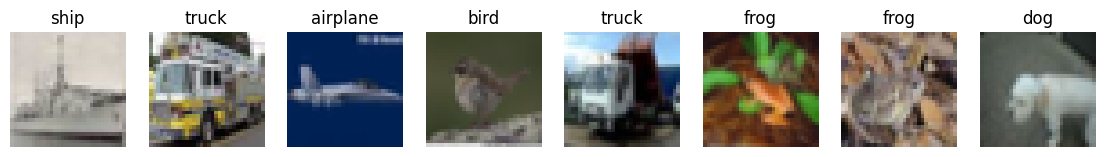

In [18]:
import matplotlib.pyplot as plt 
dataiter = iter(train_loader)
images, labels = next(dataiter)
# 다시 실행
show_images_batch(images, labels, n=8)

In [19]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes = 10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,kernel_size=3, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*8*8,128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self,x):
        # x: (N,3,32,32)
        x = self.features(x)
        # x: (N, 64,8,8)
        x = self.classifier(x)
        # x: (N, 10) logits
        return x        


In [20]:
model = SmallCNN(num_classes=10).to(device)
print(model)

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [21]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 1e-3)
print(criterion)
print(optimizer)

CrossEntropyLoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


- model.train()
- device
- optimizer.zero_grad()
- forward
- loss
- backward
- optimizer.step()

In [22]:
def accuracy_top1(logits, labels):
    preds = logits.argmax(dim=1)
    return (preds == labels).float().mean().item()

In [23]:
def train_one_epoch(model, loader):
    model.train()
    total_loss = 0.0
    total_acc = 0.0
    n = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True) # imgaes 오타 수정
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_acc += accuracy_top1(logits, labels)

        n += 1

    return total_loss / max(n,1), total_acc / max(n,1)

: 

: 

: 

In [24]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_acc = 0.0
    n = 0

    for images, labels in loader:
        images = images.to(device,non_blocking=True)
        labels = labels.to(device,non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)

        total_loss += loss.item()
        total_acc += accuracy_top1(logits, labels) 
        n += 1


    return total_loss / max(n,1), totla_acc / max(n, 1)    

- 데이터 1배치 -> 200~500 step 반복

In [25]:
images_1, labels_1 = next(iter(train_loader))
images_1 = images_1.to(device)
labels_1 = labels_1.to(device)

tmp_model = SmallCNN(num_classes = 10).to(device)
tmp_optimizer = optim.Adam(tmp_model.parameters(),lr = 1e-3)
tmp_criterion = nn.CrossEntropyLoss()

tmp_model.train()

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [26]:
for step in range(200):
    tmp_optimizer.zero_grad(set_to_none = True)
    logits = tmp_model(images_1)
    loss = tmp_criterion(logits, labels_1)
    loss.backward()
    tmp_optimizer.step()

    if (step+1) % 20 == 0:
        acc = (logits.argmax(dim=1)==labels_1).float().mean().item()
        print(loss.item(),acc)

0.9691347479820251 0.734375
0.0779268741607666 1.0
0.0052756816148757935 1.0
0.0018517484422773123 1.0
0.0012362711131572723 1.0
0.0009699487127363682 1.0
0.00079528265632689 1.0
0.0006661315564997494 1.0
0.0005661105387844145 1.0
0.00048685530782677233 1.0


In [27]:
model =  SmallCNN(num_classes=10).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

history = {'train_loss':[],'train_acc':[],'test_loss':[],'test_acc':[]}

epochs = 3

In [28]:
import time

for epoch in range(epochs):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    te_loss, te_acc = evaluate(model, test_loader)
    dt = time.time() - 10

    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['test_loss'].append(te_loss)
    history['test_acc'].append(te_acc)

    print(f'[epoch] {epoch+1}/{epochs}',{tr_loss},{tr_acc},{te_loss},{te_acc},{dt})

KeyboardInterrupt: 

Text(0.5, 1.0, 'Loss')

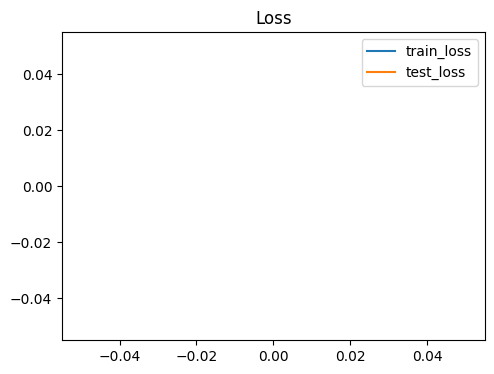

In [39]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history['train_loss'],label='train_loss')
plt.plot(history['test_loss'],label='test_loss')
plt.legend(); plt.title('Loss')

In [1]:
import random
import time
import math
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
print('torch:', torch.__version__)
print('torchvision:', torchvision.__version__)


torch: 2.9.0+cpu
torchvision: 0.24.0+cpu


In [3]:
def load_resnet18(num_classes=10, freeze_backbone=True):
    try:
        from torchvision.models import ResNet18_Weights
        m = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    except Exception:
        m = models.resnet18(pretrained=True)
        
    in_features = m.fc.in_features
    m.fc = nn.Linear(in_features, num_classes)
    if freeze_backbone:
        for name, p in m.named_parameters():
            p.requires_grad = False
        for p in m.fc.parameters():
            p.requires_grad = True
    return m
resnet = load_resnet18(num_classes=10, freeze_backbone=True)
trainable = sum(p.numel() for p in resnet.parameters() if p.requires_grad)
total = sum(p.numel() for p in resnet.parameters())
print(f'trainable params: {trainable:,} / {total:,} ({trainable/total*100:.2f}%)')

trainable params: 5,130 / 11,181,642 (0.05%)


In [4]:
imagenet_mean = [0.485,0.456,0.406]
imagenet_std = [0.229,0.224,0.225]
transform_day1 = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean,std = imagenet_std)
])

In [5]:
ds_day1 = datasets.CIFAR10(root='./data',train=False,download=False,transform=transform_day1)
img, lab = ds_day1[0]
print(img.shape,img.dtype)

RuntimeError: Dataset not found or corrupted. You can use download=True to download it

In [6]:
x = img.unsqueeze(0).to(device)
resnet.eval()
with torch.no_grad():
    logits = resnet(x)
print(logits.shape)

NameError: name 'img' is not defined

In [33]:
def set_trainable_layer4(m: nn.Module, train_layer4: bool = True):
    # 먼저 전체 freeze
    for p in m.parameters():
        p.requires_grad = False
    # head는 항상 학습
    for p in m.fc.parameters():
        p.requires_grad = True
    # layer4만 추가 학습
    if train_layer4:
        for p in m.layer4.parameters():
            p.requires_grad = True
resnet_ft = load_resnet18(num_classes=10, freeze_backbone=False).to(device)
set_trainable_layer4(resnet_ft, train_layer4=True)
trainable = sum(p.numel() for p in resnet_ft.parameters() if p.requires_grad)
total = sum(p.numel() for p in resnet_ft.parameters())
print(f'trainable params: {trainable:,} / {total:,} ({trainable/total*100:.2f}%)')

trainable params: 8,398,858 / 11,181,642 (75.11%)


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [3]:
IMAGENET_MEAN = [0.485,0.456,0.406]
IMAGENET_STD = [0.229,0.224,0.225]

train_transform  = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN,std=IMAGENET_STD),
])

In [4]:
test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

In [5]:
DATA_DIR = "./data"
train_dataset = datasets.CIFAR10(
    root=DATA_DIR, train=True, download=True, transform=train_transform
)
test_dataset = datasets.CIFAR10(
    root=DATA_DIR, train=False, download=True, transform=test_transform
)
class_names = train_dataset.classes
num_classes = len(class_names)
print("Classes:", class_names)
# DataLoader: Day-1은 설명이 길어 epoch를 크게 하지 않는다.
BATCH_SIZE = 64
NUM_WORKERS = 2  # Colab에서 너무 크게 잡으면 오히려 느려질 수 있음
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
print("Train size:", len(train_dataset), "| Test size:", len(test_dataset))

100%|██████████| 170M/170M [00:03<00:00, 43.5MB/s] 


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train size: 50000 | Test size: 10000


In [8]:
train_targets = np.array(train_dataset.targets)
test_targets  = np.array(test_dataset.targets)

In [6]:
def plot_class_distribution(targets, title):
    counts = np.bincount(targets, minlenght = num_classes)
    plt.figure(figsize=(10,3))
    plt.bar(range(num_classes),counts)
    plt.xticks(range(num_classes),classes_names,rotation=45)
    plt.title(title)
    plt.ylabel(title)
    plt.show()
    return counts

In [9]:
train_counts = plot_class_distribution(train_targets)
test_counts = plot_class_distribution(test_targets)

TypeError: plot_class_distribution() missing 1 required positional argument: 'title'

In [10]:
def denormalize(img_tensor, mean=IMAGENET_MEAN, std = IMAGENET_STD):
    img = img_tensor.clone().cpu()
    for c in range(3):
        img[c] = img[c] * std[c] + mean[c]
    img = img.clamp(0,1)
    return img    

In [11]:
def show_batch(loader, class_names, n = 8):
    images, labels = next(iter(loader))
    images = images[:n]
    labels = labels[:n]

    plt.figure(figsize=(16,4))
    for i in range(n):
        img = denormalize(images[i])
        plt.subplot(1,n,i+1)
        plt.imshow(img.permute(1,2,0))
        plt.title(class_names[labels[i]])
        plt.axis('off')
        plt.show()

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


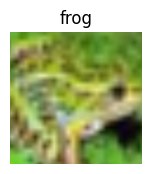

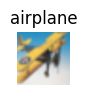

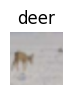

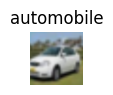

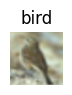

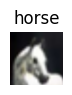

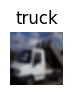

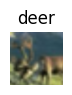

In [12]:
show_batch(train_loader, class_names, n = 8)

In [14]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 307MB/s]


In [16]:
model.fc = nn.Linear(model.fc.in_features, num_classes)

FREEZE_BACKBONE_FIRST = True

if FREEZE_BACKBONE_FIRST:
    for name, param in model.named_parameters():
        if not name.startswith("fc."):
            param.requires_grad = False

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {trainable:,} / Total params: {total:,}")

Trainable params: 5,130 / Total params: 11,181,642


In [17]:
criterion = nn.CrossEntropyLoss()
# optimizer는 'requires_grad=True'인 파라미터만 업데이트
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
# (선택) LR scheduler: Day-1에서는 단순하게 StepLR 정도만 소개
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)
print("Ready: criterion / optimizer / scheduler")

Ready: criterion / optimizer / scheduler


In [19]:
images, labels = next(iter(test_loader))
images = images[:4]
model.train()
with torch.no_grad():
    out_train = model(images)
model.eval()
with torch.no_grad():
    out_eval = model(images)
diff = (out_train - out_eval).abs().mean().item()
print("Mean abs diff between train-mode and eval-mode logits:", diff)

Mean abs diff between train-mode and eval-mode logits: 0.44096335768699646


#6. 학습 루프를 "검증 가능하게" 작성하기.

In [24]:
def accuracy_from_logits(logits, labels):
    preds = logits.argmax(dim = 1)
    return (preds == labels).float().mean(). item

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    epoch_loss = 0.0
    epoch_acc = 0.0
    n_batches = 0

    t0 = time()
    for images, lables in loader:
        images = images(non_blocking=True)
        labels = images(non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimzer.step()

        epoch_loss += loss.item()
        epoch_acc += accuracy_from_logits(logits, labels)
        n_batches += 1

    t1 = time()
    return epoch_loss / n_batches, epoch_acc / n_batches, (t1 - t0)     

In [26]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    epoch_loss = 0.0
    epoch_acc = 0.0
    n_batches = 0

    for images, labels in loader:
        images = images(non_blocking = True)
        labels = images(non_blocking = True)
        logits = model(images)
        loss = criterion(logits, labels)

        epoch_loss += loss.item()
        epoch_acc += accuracy_from_logits(logits,labels)
        n_batches += 1
 
    return epoch_loss / n_batches, epoch_acc / n_batches

In [27]:
images, labels = next(iter(train_loader))
tmp_model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
tmp_model.fc = nn.Linear(tmp_model.fc.in_features, num_classes)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


In [29]:
tmp_criterion = nn.CrossEntropyLoss()
tmp_optim = optim.SGD(tmp_model.parameters(), lr = 0.05, momentum= 0.9)
tmp_model.train()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [31]:
for step in range(30):
    tmp_optim.zero_grad(set_to_none = True)
    logits = tmp_model(images)
    loss = tmp_criterion(logits, labels)
    loss.backward()
    tmp_optim.step()

    acc = (logits.argmax(dim =1) == labels).float().mean().item()
    if (step+1) % 5 == 0:
        print(f"step {step+1:02d} | loss={loss.item():.4f} | acc={acc:.4f}")

step 05 | loss=0.0520 | acc=1.0000
step 10 | loss=0.0027 | acc=1.0000


KeyboardInterrupt: 